# Tugas Machine Learning – Dataset Car

**Tujuan:** melakukan analisis dan pemodelan Machine Learning berdasarkan metadata kendaraan pada dataset mobil.

Dataset ini berisi informasi mengenai mobil. Metode Machine Learning akan disesuaikan dengan kolom yang tersedia dan tujuan prediksi yang ingin dicapai. Jika dataset memiliki kolom target numerik, seperti harga mobil, metode regresi dapat digunakan. Jika target berupa kategori, metode klasifikasi dapat digunakan.

## 1. Loading

In [105]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Membaca dataset mobil
df = pd.read_csv("car_dataset_2000_rows.csv")

# Menampilkan 5 baris pertama
df.head()


,brand,model,year,engine_size,fuel_type,transmission,mileage,car_type,drive_type,price
0,Suzuki,WagonR,2022,1.2,Hybrid,Manual,5950,Hatchback,AWD,6280794
1,Toyota,Corolla,2015,2.6,Electric,CVT,154572,Truck,AWD,1363381
2,Suzuki,Swift,2008,2.8,Petrol,Manual,46908,Sedan,AWD,7678389
3,Suzuki,Cultus,2018,2.1,Diesel,CVT,165760,Hatchback,FWD,6098764
4,Kia,Sportage,2023,2.5,Electric,Automatic,143133,Sedan,FWD,6689630


## 2. Cleaning & Transforming

In [106]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         2000 non-null   str    
 1   model         2000 non-null   str    
 2   year          2000 non-null   int64  
 3   engine_size   2000 non-null   float64
 4   fuel_type     2000 non-null   str    
 5   transmission  2000 non-null   str    
 6   mileage       2000 non-null   int64  
 7   car_type      2000 non-null   str    
 8   drive_type    2000 non-null   str    
 9   price         2000 non-null   int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 156.4 KB


In [107]:
# Statistik deskriptif (include='all' supaya kolom teks ikut tampil)
df.describe(include="all")

,brand,model,year,engine_size,fuel_type,transmission,mileage,car_type,drive_type,price
count,2000,2000,2000.00000,2000.000000,2000,2000,2000.000000,2000,2000,2.000000e+03
unique,5,18,NaN,NaN,4,3,NaN,4,3,NaN
top,Toyota,Cerato,NaN,NaN,Diesel,Manual,NaN,Truck,FWD,NaN
freq,417,150,NaN,NaN,524,708,NaN,522,692,NaN
mean,NaN,NaN,2014.13250,2.396300,NaN,NaN,103180.273500,NaN,NaN,4.345622e+06
std,NaN,NaN,5.46158,0.928724,NaN,NaN,55391.847545,NaN,NaN,2.069889e+06
min,NaN,NaN,2005.00000,0.800000,NaN,NaN,5037.000000,NaN,NaN,8.012850e+05
25%,NaN,NaN,2009.00000,1.600000,NaN,NaN,55877.500000,NaN,NaN,2.585088e+06
50%,NaN,NaN,2014.00000,2.400000,NaN,NaN,102444.000000,NaN,NaN,4.304987e+06
75%,NaN,NaN,2019.00000,3.200000,NaN,NaN,149161.750000,NaN,NaN,6.099470e+06


In [108]:
# Cek missing value
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

**Catatan Data:**
- Dataset terdiri dari 2.000 baris data dan 10 kolom yang berisi informasi mengenai kendaraan.
- Berdasarkan pemeriksaan awal, tidak ditemukan missing value pada seluruh kolom dataset.
- Kolom terdiri dari data kategorikal, seperti `brand`, `model`, `fuel_type`, `transmission`, `car_type`, dan `drive_type`, serta data numerik, seperti `year`, `engine_size`, `mileage`, dan `price`.
- Dataset siap digunakan untuk tahap preprocessing dan pemodelan Machine Learning setelah dilakukan pemeriksaan lebih lanjut terhadap konsistensi dan kualitas data.

In [109]:

# =========================
# DATA CLEANING DATASET MOBIL
# =========================

# Cek missing value sebelum cleaning
print("Missing Value Sebelum Cleaning:")
display(df.isnull().sum())

# Penanganan missing value
# Kolom numerik menggunakan median
kolom_numerik = df.select_dtypes(include='number').columns

for col in kolom_numerik:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Kolom kategorikal menggunakan 'Unknown'
kolom_kategorikal = df.select_dtypes(
    include=['object', 'category', 'str']
).columns

for col in kolom_kategorikal:
    if df[col].isnull().any():
        df[col] = df[col].fillna('Unknown')

# Cek missing value setelah cleaning
print("\nMissing Value Setelah Cleaning:")
display(df.isnull().sum())

# Informasi dataset
print("\nUkuran Dataset:", df.shape)

# Statistik deskriptif
print("\nStatistik Deskriptif:")
display(df.describe())

# Menampilkan 5 baris pertama
print("\nContoh Data Mobil:")
display(df.head())


Missing Value Sebelum Cleaning:


brand           0
model           0
year            0
engine_size     0
fuel_type       0
transmission    0
mileage         0
car_type        0
drive_type      0
price           0
dtype: int64


Missing Value Setelah Cleaning:


brand           0
model           0
year            0
engine_size     0
fuel_type       0
transmission    0
mileage         0
car_type        0
drive_type      0
price           0
dtype: int64


Ukuran Dataset: (2000, 10)

Statistik Deskriptif:


,year,engine_size,mileage,price
count,2000.00000,2000.000000,2000.000000,2.000000e+03
mean,2014.13250,2.396300,103180.273500,4.345622e+06
std,5.46158,0.928724,55391.847545,2.069889e+06
min,2005.00000,0.800000,5037.000000,8.012850e+05
25%,2009.00000,1.600000,55877.500000,2.585088e+06
50%,2014.00000,2.400000,102444.000000,4.304987e+06
75%,2019.00000,3.200000,149161.750000,6.099470e+06
max,2023.00000,4.000000,199898.000000,7.997116e+06



Contoh Data Mobil:


,brand,model,year,engine_size,fuel_type,transmission,mileage,car_type,drive_type,price
0,Suzuki,WagonR,2022,1.2,Hybrid,Manual,5950,Hatchback,AWD,6280794
1,Toyota,Corolla,2015,2.6,Electric,CVT,154572,Truck,AWD,1363381
2,Suzuki,Swift,2008,2.8,Petrol,Manual,46908,Sedan,AWD,7678389
3,Suzuki,Cultus,2018,2.1,Diesel,CVT,165760,Hatchback,FWD,6098764
4,Kia,Sportage,2023,2.5,Electric,Automatic,143133,Sedan,FWD,6689630


In [110]:
# Cek & hapus duplikat
print("Jumlah duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape setelah drop duplikat:", df.shape)

Jumlah duplikat: 0
Shape setelah drop duplikat: (2000, 10)


### Feature Engineering

Kolom kategorikal seperti `brand`, `model`, `fuel_type`, `transmission`, `car_type`, dan `drive_type` perlu diubah menjadi fitur numerik menggunakan teknik encoding agar dapat diproses oleh algoritma Machine Learning. Sementara itu, kolom numerik seperti `year`, `engine_size`, dan `mileage` dapat digunakan sebagai fitur untuk membantu model mempelajari karakteristik kendaraan.

**Kolom `price` digunakan sebagai target prediksi**, sehingga tidak dimasukkan sebagai fitur input. Hal ini bertujuan untuk menghindari *data leakage*, yaitu kondisi ketika informasi target ikut digunakan sebagai input model sehingga hasil evaluasi menjadi tidak valid.

Sebelum pemodelan, dilakukan pemeriksaan tipe data dan konsistensi nilai. Jika algoritma yang digunakan membutuhkan penskalaan, fitur numerik dapat dinormalisasi atau distandardisasi sesuai kebutuhan. Dengan demikian, fitur yang tersedia dapat digunakan untuk membangun model Machine Learning yang memprediksi harga mobil berdasarkan karakteristik kendaraannya.

In [111]:

# =========================
# FEATURE ENGINEERING DATASET MOBIL
# =========================

fe = df.copy()

# Target prediksi: harga mobil
fe['price'] = df['price']

# Fitur numerik
fe['year'] = df['year']
fe['engine_size'] = df['engine_size']
fe['mileage'] = df['mileage']

# Fitur kategorikal
fe['brand'] = df['brand']
fe['model'] = df['model']
fe['fuel_type'] = df['fuel_type']
fe['transmission'] = df['transmission']
fe['car_type'] = df['car_type']
fe['drive_type'] = df['drive_type']

# Tampilkan hasil feature engineering
print("Ukuran dataset:", fe.shape)
print("\nKolom dataset:")
print(fe.columns.tolist())

print("\nContoh hasil feature engineering:")
display(fe.head())


Ukuran dataset: (2000, 10)

Kolom dataset:
['brand', 'model', 'year', 'engine_size', 'fuel_type', 'transmission', 'mileage', 'car_type', 'drive_type', 'price']

Contoh hasil feature engineering:


,brand,model,year,engine_size,fuel_type,transmission,mileage,car_type,drive_type,price
0,Suzuki,WagonR,2022,1.2,Hybrid,Manual,5950,Hatchback,AWD,6280794
1,Toyota,Corolla,2015,2.6,Electric,CVT,154572,Truck,AWD,1363381
2,Suzuki,Swift,2008,2.8,Petrol,Manual,46908,Sedan,AWD,7678389
3,Suzuki,Cultus,2018,2.1,Diesel,CVT,165760,Hatchback,FWD,6098764
4,Kia,Sportage,2023,2.5,Electric,Automatic,143133,Sedan,FWD,6689630


### Outlier

Pada dataset mobil, nilai pada kolom numerik seperti `year`, `engine_size`, `mileage`, dan `price` perlu diperiksa untuk mengetahui apakah terdapat outlier. Nilai yang terlihat ekstrem belum tentu merupakan kesalahan data, karena bisa saja mencerminkan karakteristik kendaraan yang memang berbeda dari kendaraan lainnya.

Oleh karena itu, outlier tidak langsung dihapus hanya berdasarkan metode IQR (*Interquartile Range*). Pemeriksaan awal dapat dilakukan menggunakan boxplot untuk melihat distribusi data dan mengidentifikasi nilai yang berada jauh dari rentang mayoritas data. Penghapusan outlier hanya dilakukan apabila ditemukan nilai yang tidak valid atau kesalahan pencatatan berdasarkan pemeriksaan lebih lanjut.

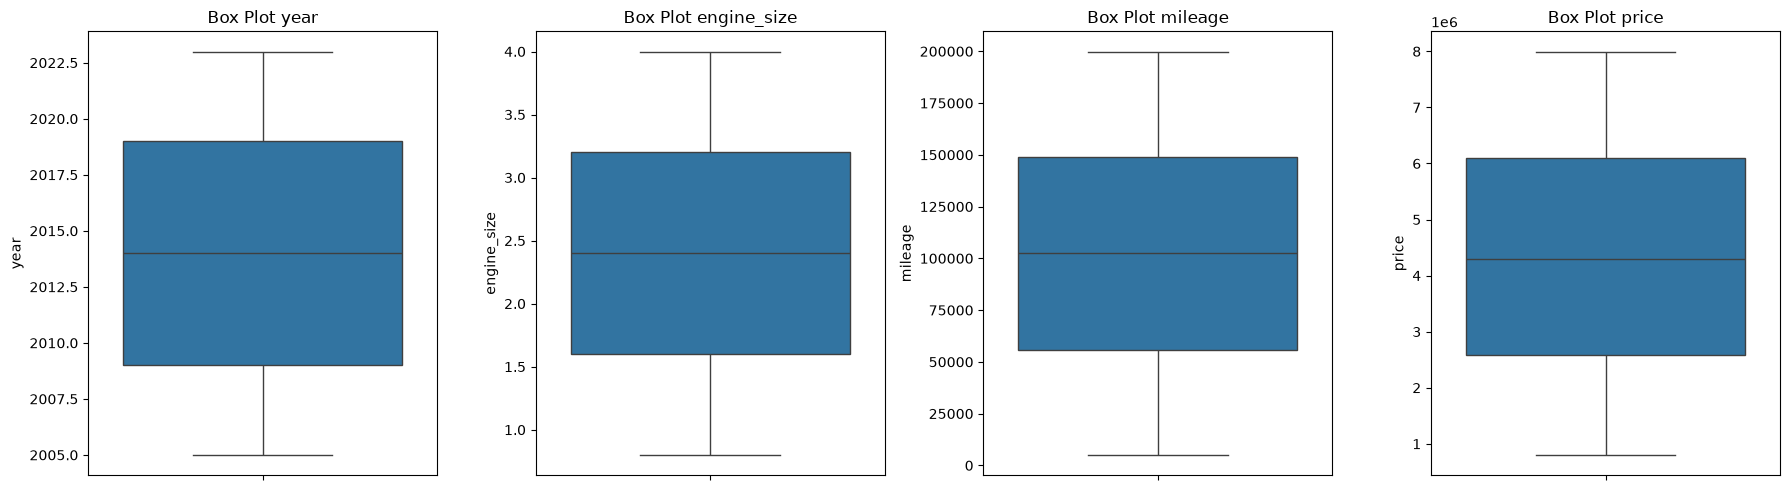

In [112]:

# =========================
# BOX PLOT DATASET MOBIL
# =========================

num_cols = ['year', 'engine_size', 'mileage', 'price']

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 5))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f'Box Plot {col}')

plt.tight_layout()
plt.show()


In [113]:
# Cek jumlah outlier (IQR) hanya sebagai informasi
Q1 = fe[num_cols].quantile(0.25)
Q3 = fe[num_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (fe[num_cols] < (Q1 - 1.5 * IQR)) | (fe[num_cols] > (Q3 + 1.5 * IQR))
print(outlier_mask.sum())

year           0
engine_size    0
mileage        0
price          0
dtype: int64


In [114]:

# =========================
# PEMERIKSAAN OUTLIER DATASET MOBIL
# =========================

# Kolom numerik yang diperiksa
kolom_outlier = ['year', 'engine_size', 'mileage', 'price']

for col in kolom_outlier:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    jumlah_outlier = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f'{col}: {jumlah_outlier} data terdeteksi sebagai outlier')

# Data asli tidak dihapus atau diubah


year: 0 data terdeteksi sebagai outlier
engine_size: 0 data terdeteksi sebagai outlier
mileage: 0 data terdeteksi sebagai outlier
price: 0 data terdeteksi sebagai outlier


### Encoding

Kolom kategorikal pada dataset mobil, seperti `brand`, `model`, `fuel_type`, `transmission`, `car_type`, dan `drive_type`, diubah menjadi representasi numerik menggunakan teknik encoding agar dapat diproses oleh algoritma Machine Learning.

Teknik **One-Hot Encoding** dapat digunakan untuk fitur kategorikal nominal karena tidak memberikan urutan atau tingkatan palsu antar kategori. Sementara itu, kolom numerik seperti `year`, `engine_size`, dan `mileage` tetap dipertahankan sebagai nilai numerik.

Kolom `price` digunakan sebagai target prediksi dalam model regresi, sehingga tidak perlu diubah menjadi label kategori 0 dan 1. Encoding dan preprocessing dilakukan pada fitur input tanpa memasukkan kolom target ke dalam proses tersebut.

In [115]:

# =========================
# 6. ENCODING DATASET MOBIL
# =========================

# Target: harga mobil
y = df['price']

# Fitur: semua kolom kecuali target
X = df.drop(columns=['price'])

# One-Hot Encoding untuk fitur kategorikal
X = pd.get_dummies(
    X,
    columns=[
        'brand',
        'model',
        'fuel_type',
        'transmission',
        'car_type',
        'drive_type'
    ],
    drop_first=True,
    dtype=int
)

# Pastikan semua fitur numerik
X = X.astype(float)

# Tampilkan hasil
print("Ukuran fitur X:", X.shape)
print("Ukuran target y:", y.shape)

print("\nContoh fitur:")
display(X.head())

print("\nContoh target harga:")
display(y.head())


Ukuran fitur X: (2000, 34)
Ukuran target y: (2000,)

Contoh fitur:


,year,engine_size,mileage,brand_Hyundai,brand_Kia,brand_Suzuki,brand_Toyota,model_Alto,model_BR-V,model_Camry,...,fuel_type_Electric,fuel_type_Hybrid,fuel_type_Petrol,transmission_CVT,transmission_Manual,car_type_SUV,car_type_Sedan,car_type_Truck,drive_type_FWD,drive_type_RWD
0,2022.0,1.2,5950.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,2015.0,2.6,154572.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2008.0,2.8,46908.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,2018.0,2.1,165760.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,2023.0,2.5,143133.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0



Contoh target harga:


0    6280794
1    1363381
2    7678389
3    6098764
4    6689630
Name: price, dtype: int64

## 3. EDA

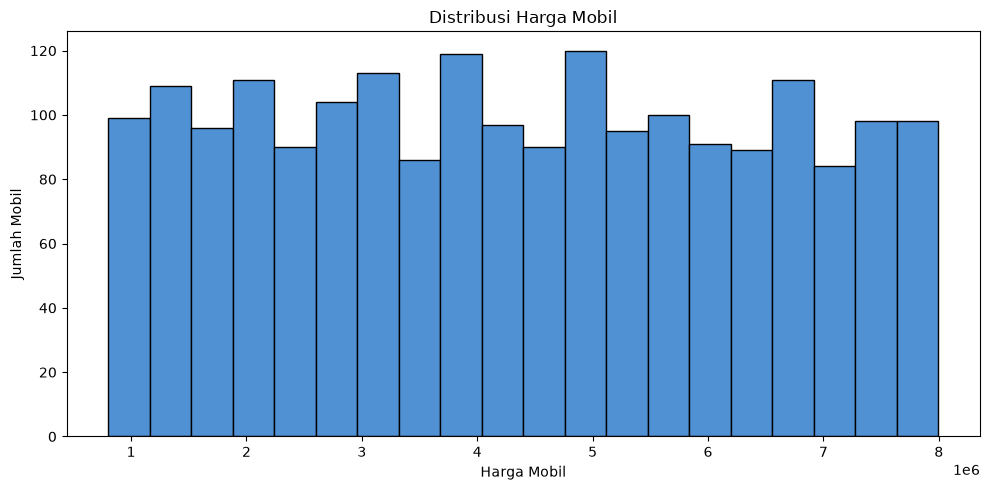

In [116]:

# =========================
# DISTRIBUSI HARGA MOBIL
# =========================

plt.figure(figsize=(10, 5))

df['price'].plot(
    kind='hist',
    bins=20,
    color='#5091d4',
    edgecolor='black'
)

plt.title('Distribusi Harga Mobil')
plt.xlabel('Harga Mobil')
plt.ylabel('Jumlah Mobil')
plt.tight_layout()
plt.show()


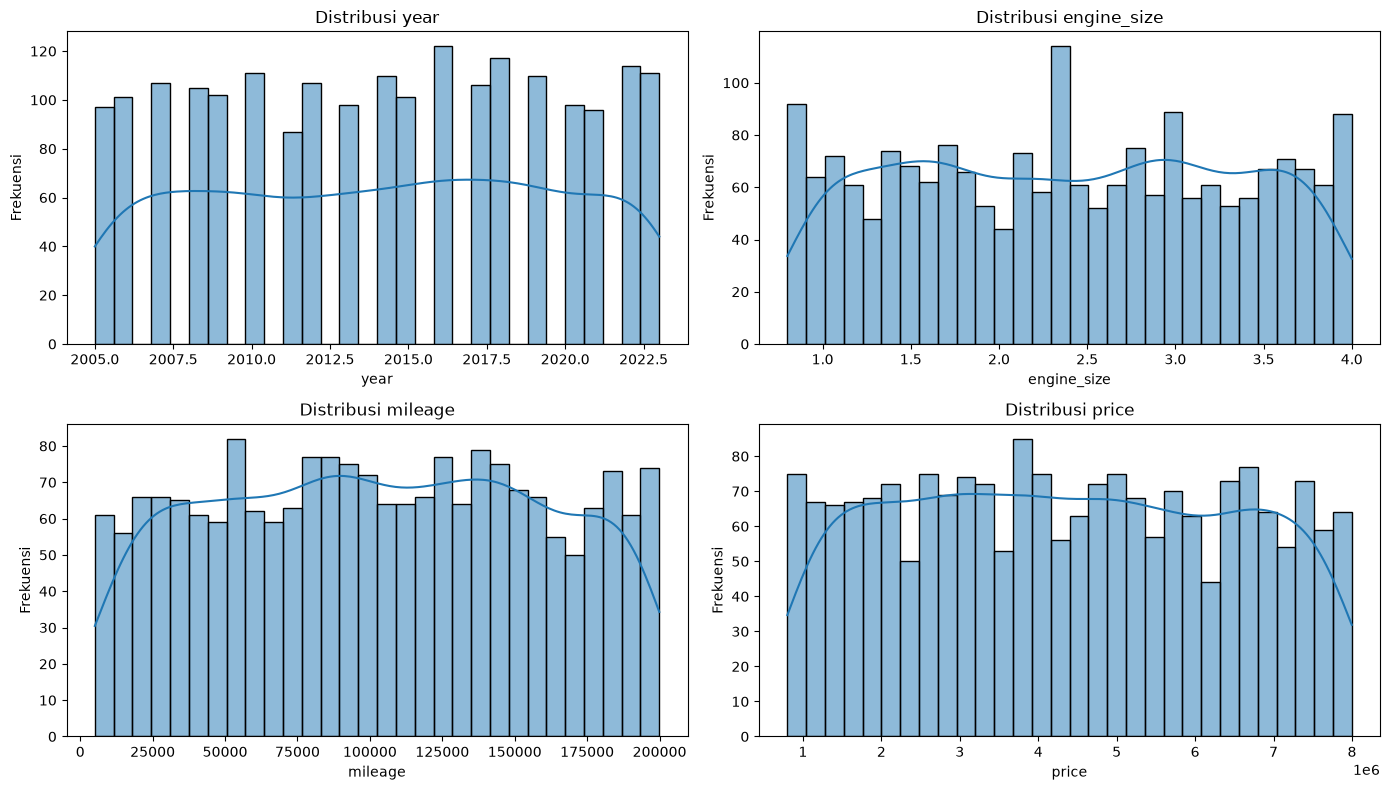

In [117]:

# =========================
# DISTRIBUSI FITUR NUMERIK MOBIL
# =========================

cols = ['year', 'engine_size', 'mileage', 'price']

plt.figure(figsize=(14, 8))

for i, col in enumerate(cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()


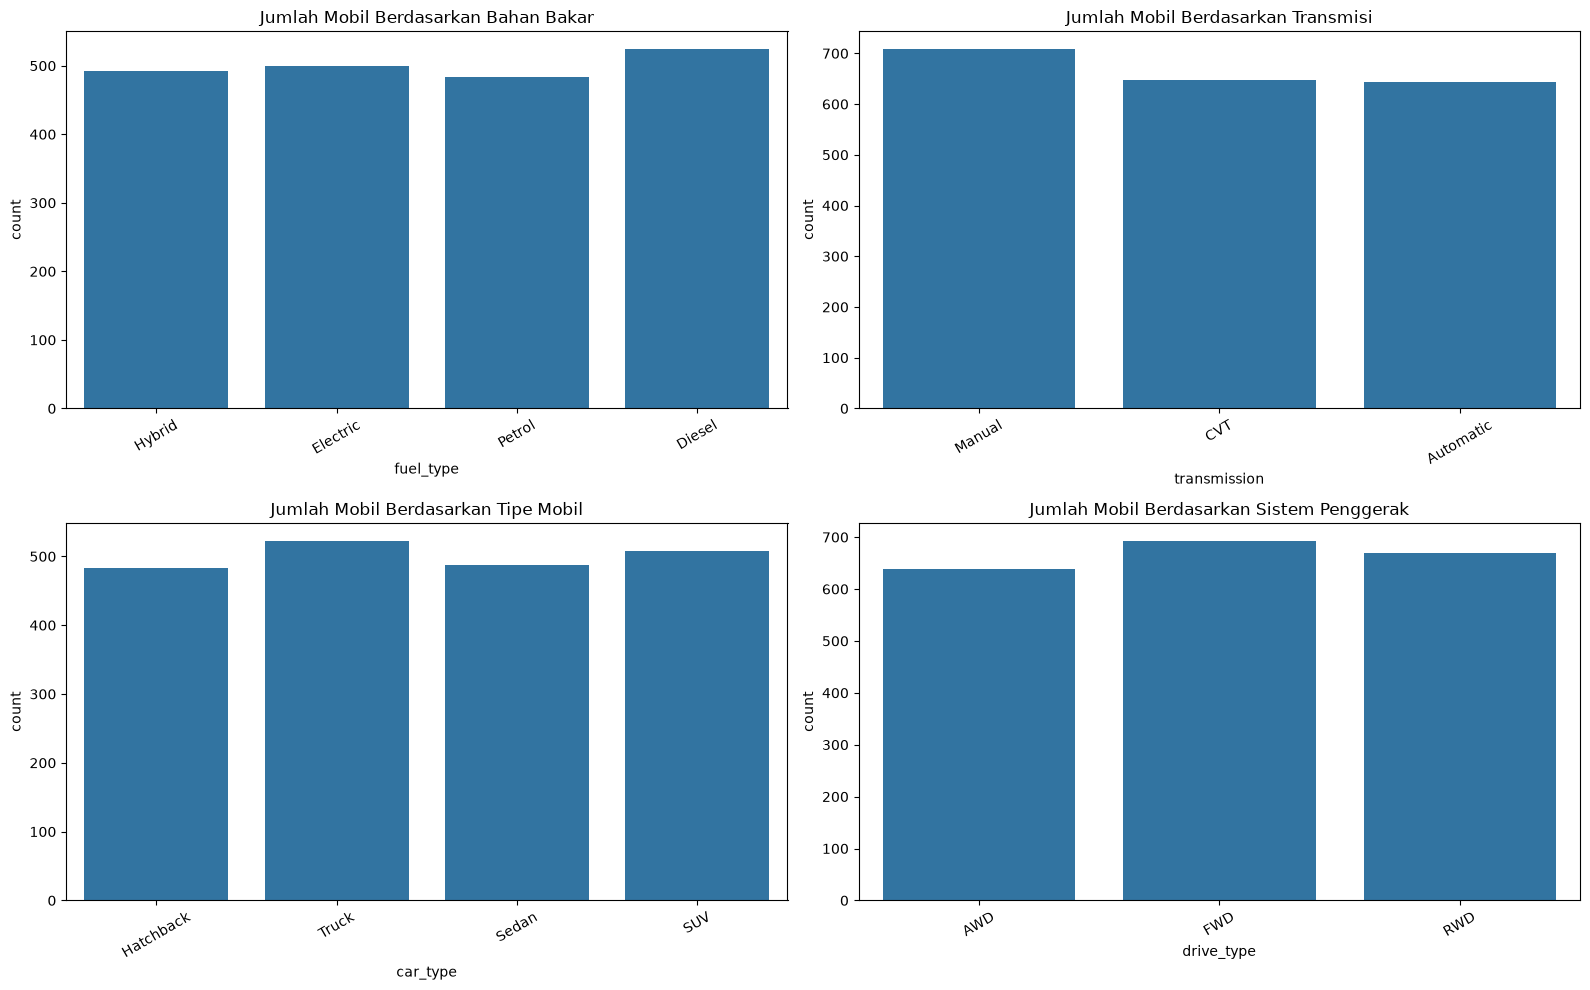

In [118]:

# =========================
# DISTRIBUSI FITUR KATEGORIKAL MOBIL
# =========================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Distribusi jenis bahan bakar
sns.countplot(data=df, x='fuel_type', ax=axes[0, 0])
axes[0, 0].set_title('Jumlah Mobil Berdasarkan Bahan Bakar')
axes[0, 0].tick_params(axis='x', rotation=30)

# Distribusi jenis transmisi
sns.countplot(data=df, x='transmission', ax=axes[0, 1])
axes[0, 1].set_title('Jumlah Mobil Berdasarkan Transmisi')
axes[0, 1].tick_params(axis='x', rotation=30)

# Distribusi tipe mobil
sns.countplot(data=df, x='car_type', ax=axes[1, 0])
axes[1, 0].set_title('Jumlah Mobil Berdasarkan Tipe Mobil')
axes[1, 0].tick_params(axis='x', rotation=30)

# Distribusi sistem penggerak
sns.countplot(data=df, x='drive_type', ax=axes[1, 1])
axes[1, 1].set_title('Jumlah Mobil Berdasarkan Sistem Penggerak')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


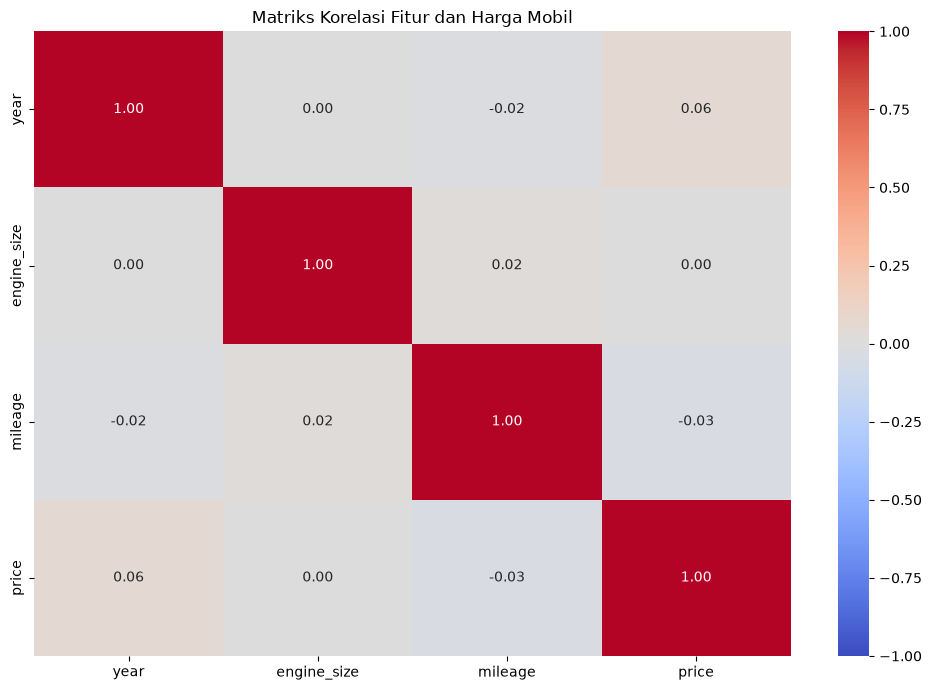

In [119]:

# =========================
# KORELASI FITUR NUMERIK MOBIL
# =========================

# Pilih fitur numerik dan target harga
data_corr = df[
    ['year', 'engine_size', 'mileage', 'price']
].copy()

# Hitung korelasi
corr_matrix = data_corr.corr()

# Visualisasi heatmap korelasi
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Matriks Korelasi Fitur dan Harga Mobil')
plt.tight_layout()
plt.show()


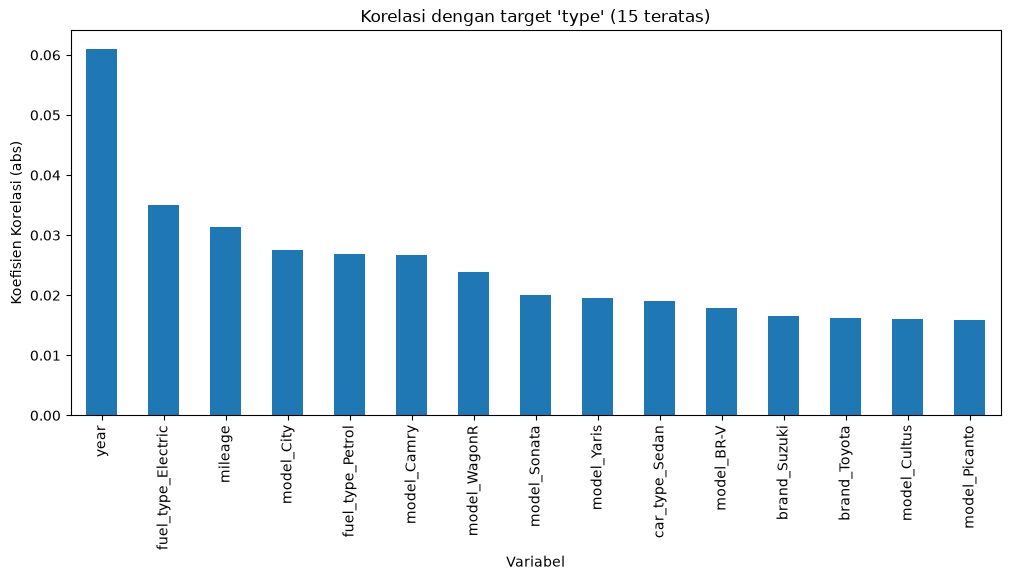

In [120]:
# Korelasi semua fitur terhadap target 'type'
target_corr = X.corrwith(y).abs().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
target_corr.head(15).plot(kind='bar')
plt.title("Korelasi dengan target 'type' (15 teratas)")
plt.xlabel('Variabel')
plt.ylabel('Koefisien Korelasi (abs)')
plt.show()

## 4. Splitting

Pembagian dataset dilakukan menjadi data latih (*training data*) dan data uji (*testing data*) sebelum proses scaling atau preprocessing yang mempelajari parameter dari data. Pembagian ini bertujuan untuk mencegah kebocoran data (*data leakage*) dari data uji ke data latih.

Pada penelitian ini, dataset mobil dibagi dengan proporsi **80% data latih dan 20% data uji**. Kolom `price` digunakan sebagai target prediksi, sedangkan kolom lainnya yang relevan digunakan sebagai fitur input. Karena target `price` berupa data numerik untuk regresi, parameter `stratify=y` tidak digunakan secara langsung seperti pada klasifikasi. Jika diperlukan, distribusi harga pada data latih dan data uji dapat dibandingkan untuk memastikan keduanya cukup representatif.

In [121]:

# =========================
# 7. SPLITTING DATASET
# =========================

from sklearn.model_selection import train_test_split

# Pisahkan data training 80% dan testing 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("Jumlah fitur:", X_train.shape[1])
print("Training dan testing berhasil dipisahkan!")


Jumlah data training: 1600
Jumlah data testing: 400
Jumlah fitur: 34
Training dan testing berhasil dipisahkan!


In [122]:

# =========================
# CEK HASIL SPLITTING DATA
# =========================

print("Jumlah seluruh data :", len(X))
print("Jumlah data latih    :", len(X_train))
print("Jumlah data test     :", len(X_test))
print()

print("Rentang harga data latih:")
print(y_train.describe())

print("\nRentang harga data test:")
print(y_test.describe())


Jumlah seluruh data : 2000
Jumlah data latih    : 1600
Jumlah data test     : 400

Rentang harga data latih:
count    1.600000e+03
mean     4.336113e+06
std      2.069393e+06
min      8.012850e+05
25%      2.565010e+06
50%      4.264762e+06
75%      6.099470e+06
max      7.997116e+06
Name: price, dtype: float64

Rentang harga data test:
count    4.000000e+02
mean     4.383661e+06
std      2.074027e+06
min      8.081870e+05
25%      2.687529e+06
50%      4.519775e+06
75%      6.095526e+06
max      7.975190e+06
Name: price, dtype: float64


In [123]:

# =========================
# STANDARDISASI FITUR
# =========================

from sklearn.preprocessing import StandardScaler

# Buat scaler
scaler = StandardScaler()

# Fit hanya pada data latih
X_train_scaled = scaler.fit_transform(X_train)

# Transform data test menggunakan scaler yang sama
X_test_scaled = scaler.transform(X_test)

print("Standardisasi data berhasil!")
print("Ukuran data latih:", X_train_scaled.shape)
print("Ukuran data test :", X_test_scaled.shape)


Standardisasi data berhasil!
Ukuran data latih: (1600, 34)
Ukuran data test : (400, 34)


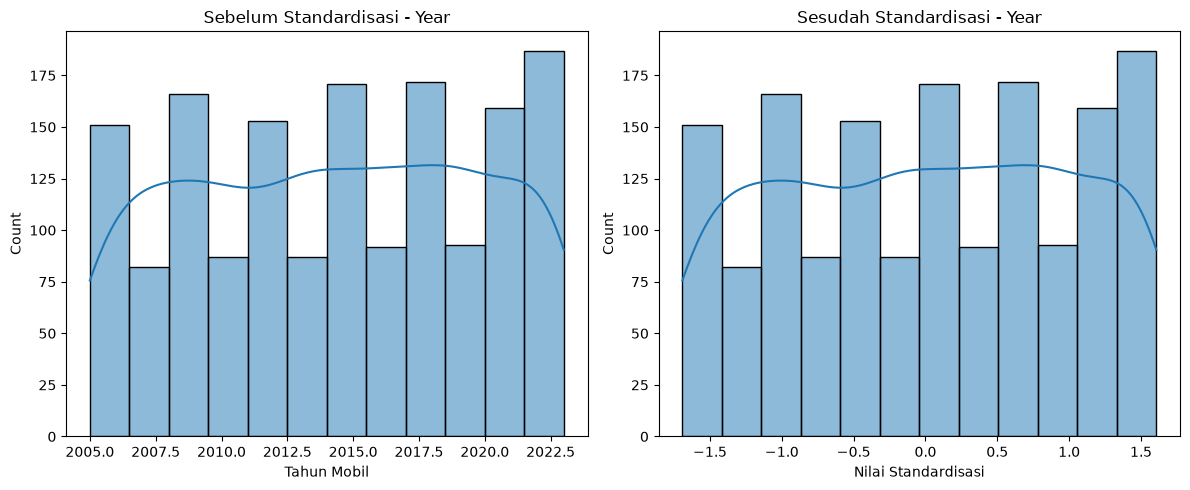

In [124]:

# ==============================
# HISTOGRAM SEBELUM VS SESUDAH STANDARDISASI
# ==============================

from sklearn.preprocessing import StandardScaler

# Standardisasi ulang agar variabelnya pasti tersedia
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Pilih fitur tahun mobil
fitur = 'year'
idx = list(X_train.columns).index(fitur)

plt.figure(figsize=(12, 5))

# Sebelum standardisasi
plt.subplot(1, 2, 1)
sns.histplot(X_train[fitur], kde=True)
plt.title('Sebelum Standardisasi - Year')
plt.xlabel('Tahun Mobil')

# Sesudah standardisasi
plt.subplot(1, 2, 2)
sns.histplot(X_train_scaled[:, idx], kde=True)
plt.title('Sesudah Standardisasi - Year')
plt.xlabel('Nilai Standardisasi')

plt.tight_layout()
plt.show()


## 5. Modeling

Karena target yang digunakan adalah `price` atau harga mobil dalam bentuk numerik, metode Machine Learning yang digunakan adalah regresi. Beberapa algoritma regresi diterapkan untuk membandingkan kemampuan model dalam memprediksi harga mobil berdasarkan karakteristik kendaraan.

| Modul (Regresi) | Model yang Digunakan |
|---|---|
| Least Angle Regression (LARS) | Least Angle Regression |
| Linear Regression | Linear Regression sebagai baseline |
| Gradient Boosting Regressor (GBR) | Gradient Boosting Regressor |
| Model pembanding | Random Forest Regressor |

Linear Regression digunakan sebagai model dasar (*baseline*) karena pendekatannya sederhana dan mudah diinterpretasikan. Least Angle Regression digunakan sebagai alternatif regresi, sedangkan Gradient Boosting Regressor dan Random Forest Regressor digunakan untuk mempelajari pola hubungan yang lebih kompleks antara fitur kendaraan dan harga mobil.

Seluruh model dievaluasi menggunakan data uji yang sama agar hasil perbandingan lebih adil. Model terbaik ditentukan berdasarkan metrik evaluasi regresi, seperti Mean Absolute Error (MAE), Mean Squared Error (MSE), dan koefisien determinasi (\(R^2\)).

In [125]:

# =========================
# 8. MODELING REGRESI
# =========================

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Model 1: Linear Regression
LR = LinearRegression()
LR.fit(X_train_scaled, y_train)

# Model 2: Decision Tree Regressor
DT = DecisionTreeRegressor(
    max_depth=6,
    random_state=42
)
DT.fit(X_train, y_train)

# Model 3: Random Forest Regressor
RF = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
RF.fit(X_train, y_train)

# Model 4: Gradient Boosting Regressor
GBR = GradientBoostingRegressor(
    random_state=42
)
GBR.fit(X_train, y_train)

print("Semua model regresi berhasil dilatih!")


Semua model regresi berhasil dilatih!


In [126]:

# =========================
# 9. EVALUASI MODEL REGRESI
# =========================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluasi(nama, model, X_test_data, y_test_data):
    pred = model.predict(X_test_data)

    mae = mean_absolute_error(y_test_data, pred)
    mse = mean_squared_error(y_test_data, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_data, pred)

    return {
        'Model': nama,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

# Bandingkan empat model
hasil = [
    evaluasi('Linear Regression', LR, X_test_scaled, y_test),
    evaluasi('Decision Tree', DT, X_test, y_test),
    evaluasi('Random Forest', RF, X_test, y_test),
    evaluasi('Gradient Boosting', GBR, X_test, y_test)
]

df_results = pd.DataFrame(hasil).set_index('Model').round(4)

display(df_results)


,MAE,MSE,RMSE,R2 Score
Model,,,,
Linear Regression,1.818910e+06,4.443859e+12,2.108046e+06,-0.0357
Decision Tree,1.886587e+06,4.843938e+12,2.200895e+06,-0.1289
Random Forest,1.872102e+06,4.668090e+12,2.160576e+06,-0.0879
Gradient Boosting,1.840285e+06,4.557766e+12,2.134893e+06,-0.0622


In [127]:

# IMPORT LIBRARY DAN LOAD DATASET MOBIL
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("car_dataset_2000_rows.csv")

# Pastikan kolom sesuai dataset mobil
print("Ukuran dataset:", df.shape)
print("Nama kolom:", df.columns.tolist())
print(df.head())


Ukuran dataset: (2000, 10)
Nama kolom: ['brand', 'model', 'year', 'engine_size', 'fuel_type', 'transmission', 'mileage', 'car_type', 'drive_type', 'price']
    brand     model  year  engine_size fuel_type transmission  mileage  \
0  Suzuki    WagonR  2022          1.2    Hybrid       Manual     5950   
1  Toyota   Corolla  2015          2.6  Electric          CVT   154572   
2  Suzuki     Swift  2008          2.8    Petrol       Manual    46908   
3  Suzuki    Cultus  2018          2.1    Diesel          CVT   165760   
4     Kia  Sportage  2023          2.5  Electric    Automatic   143133   

    car_type drive_type    price  
0  Hatchback        AWD  6280794  
1      Truck        AWD  1363381  
2      Sedan        AWD  7678389  
3  Hatchback        FWD  6098764  
4      Sedan        FWD  6689630  


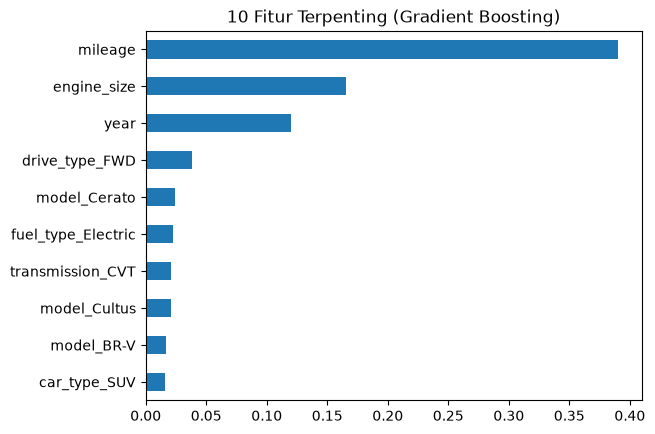

In [128]:

imp = pd.Series(GBR.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('10 Fitur Terpenting (Gradient Boosting)')
plt.show()


In [129]:
from sklearn.ensemble import GradientBoostingClassifier
GBC = GradientBoostingClassifier(random_state=184).fit(X_train, y_train)

c:\Users\dava\Documents\SEMESTER 5\MACHINE LEARNING\.venv\Lib\site-packages\sklearn\ensemble\_gb.py:1534: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)


In [130]:

joblib.dump(GBC, 'best_model.joblib')

with open('best_model.pkl', 'wb') as file:
    pickle.dump(GBC, file)
